<a href="https://colab.research.google.com/github/1BF24CS033/BIS/blob/main/Ant_Colony_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration  |  Best Distance  |  Avg Distance  
------------------------------------------------
    1      |     335.60      |     499.13     
    25     |     320.53      |     351.09     
    50     |     320.53      |     357.51     
    75     |     320.53      |     358.41     
   100     |     320.53      |     373.47     
Optimal Distance Found: 320.53
Optimal City Sequence: [4, np.int64(1), np.int64(6), np.int64(10), np.int64(14), np.int64(9), np.int64(2), np.int64(7), np.int64(11), np.int64(8), np.int64(13), np.int64(3), np.int64(5), np.int64(0), np.int64(12)]


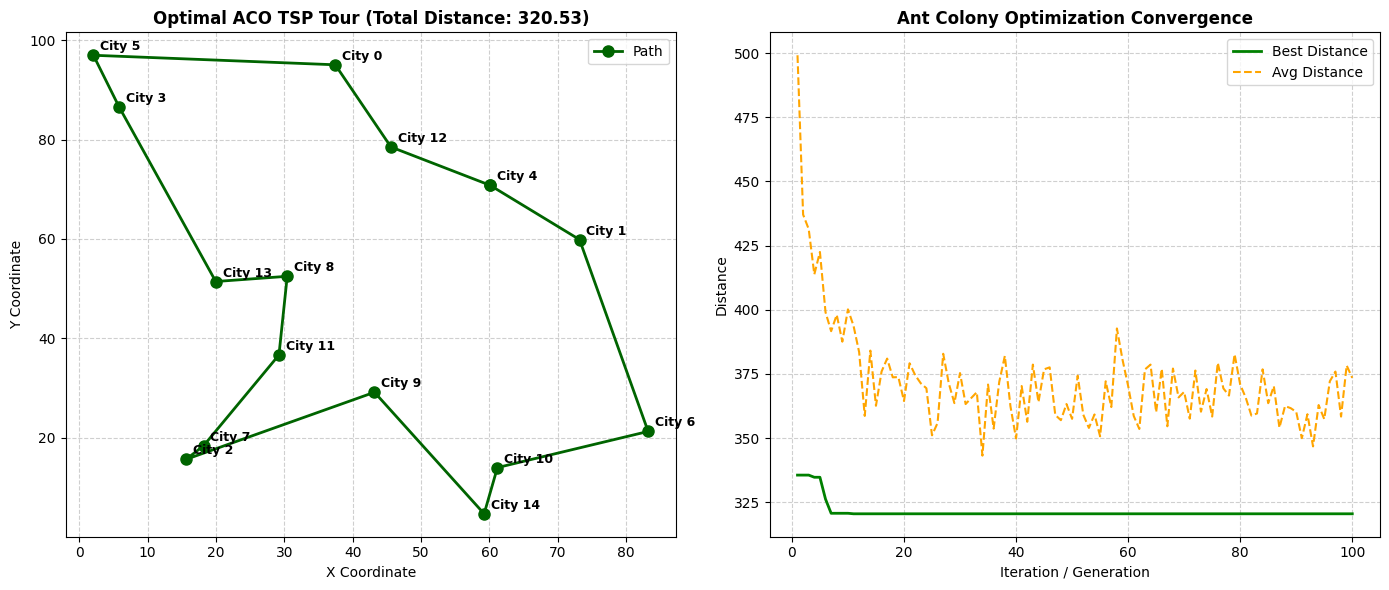

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Problem Setup & Initialization
# ==========================================
np.random.seed(42)  # For reproducible results

num_cities = 15
# Generate random 2D coordinates for cities
cities = np.random.rand(num_cities, 2) * 100

# Precompute distance matrix
dist_matrix = np.zeros((num_cities, num_cities))
for i in range(num_cities):
    for j in range(num_cities):
        if i != j:
            dist_matrix[i, j] = np.linalg.norm(cities[i] - cities[j])
        else:
            dist_matrix[i, j] = 1e-10  # Avoid division by zero

def compute_total_distance(tour, city_coords):
    """Calculates total Euclidean route distance for a given city permutation."""
    dist = 0.0
    for i in range(len(tour)):
        p1 = city_coords[tour[i]]
        p2 = city_coords[tour[(i + 1) % len(tour)]]
        dist += np.linalg.norm(p1 - p2)
    return dist

# ==========================================
# 2. ACO Hyperparameters
# ==========================================
num_ants = 20
max_iterations = 100
alpha = 1.0       # Influence of pheromone
beta = 2.0        # Influence of heuristic information (1/distance)
evaporation_rate = 0.5
Q = 100.0         # Pheromone constant

# Initialize pheromones
pheromones = np.ones((num_cities, num_cities))

best_tour = None
best_distance = float('inf')
history_best_dist = []
history_avg_dist = []

# ==========================================
# 3. ACO Optimization Loop
# ==========================================
print(f"{'Iteration':^10} | {'Best Distance':^15} | {'Avg Distance':^15}")
print("-" * 48)

for iteration in range(1, max_iterations + 1):
    all_tours = []
    all_distances = []

    for ant in range(num_ants):
        current_city = np.random.randint(num_cities)
        unvisited = set(range(num_cities))
        unvisited.remove(current_city)
        tour = [current_city]

        while unvisited:
            # Calculate probabilities for next city
            pheromone_values = pheromones[current_city, list(unvisited)] ** alpha
            heuristic_values = (1.0 / dist_matrix[current_city, list(unvisited)]) ** beta
            probabilities = pheromone_values * heuristic_values
            probabilities /= np.sum(probabilities)

            # Choose next city based on probabilities
            next_city = np.random.choice(list(unvisited), p=probabilities)
            tour.append(next_city)
            unvisited.remove(next_city)
            current_city = next_city

        tour_dist = compute_total_distance(tour, cities)
        all_tours.append(tour)
        all_distances.append(tour_dist)

        # Update best solution
        if tour_dist < best_distance:
            best_distance = tour_dist
            best_tour = tour.copy()

    history_best_dist.append(best_distance)
    history_avg_dist.append(np.mean(all_distances))

    # Evaporate pheromones
    pheromones *= (1.0 - evaporation_rate)

    # Deposit new pheromones
    for tour, tour_dist in zip(all_tours, all_distances):
        for i in range(num_cities):
            c1 = tour[i]
            c2 = tour[(i + 1) % num_cities]
            pheromones[c1, c2] += Q / tour_dist
            pheromones[c2, c1] += Q / tour_dist

    # Print progress every 25 iterations
    if iteration == 1 or iteration % 25 == 0 or iteration == max_iterations:
        print(f"{iteration:^10d} | {best_distance:^15.2f} | {np.mean(all_distances):^15.2f}")

print("=" * 48)
print(f"Optimal Distance Found: {best_distance:.2f}")
print(f"Optimal City Sequence: {best_tour}")

# ==========================================
# 4. Visualization & Graph Output
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Optimal Route
tour_cities = np.vstack([cities[best_tour], cities[best_tour[0]]])  # Close loop
ax1.plot(tour_cities[:, 0], tour_cities[:, 1], 'o-', color='darkgreen', markersize=8, linewidth=2, label='Path')
for i, (x, y) in enumerate(cities):
    ax1.text(x + 1, y + 1, f"City {i}", fontsize=9, fontweight='bold')

ax1.set_title(f"Optimal ACO TSP Tour (Total Distance: {best_distance:.2f})", fontsize=12, fontweight='bold')
ax1.set_xlabel("X Coordinate")
ax1.set_ylabel("Y Coordinate")
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Plot 2: Convergence History
ax2.plot(range(1, max_iterations + 1), history_best_dist, label='Best Distance', color='green', linewidth=2)
ax2.plot(range(1, max_iterations + 1), history_avg_dist, label='Avg Distance', color='orange', linestyle='--')
ax2.set_title("Ant Colony Optimization Convergence", fontsize=12, fontweight='bold')
ax2.set_xlabel("Iteration / Generation")
ax2.set_ylabel("Distance")
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()